# TP3 : Apprentissage du PMC par rétropropagation (XOR)
Ayman Ezzahir

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]]).T  
Y = np.array([[0], [1], [1], [0]]).T              
print("X :", X.shape, "\nY :", Y.shape)
print(X)
print(Y)

X : (2, 4) 
Y : (1, 4)
[[0 0 1 1]
 [0 1 0 1]]
[[0 1 1 0]]


In [2]:
# 2. Initialisation + propagation avant (architecture 2 -> 3 -> 1)
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def initialisation(sizes, seed=42, scale=1.0):
    np.random.seed(seed)
    params = {}
    for l in range(1, len(sizes)):
        params[f"W{l}"] = np.random.randn(sizes[l], sizes[l-1]) * scale
        params[f"b{l}"] = np.zeros((sizes[l], 1))
    return params

def forward(X, params):
    Z1 = params["W1"] @ X + params["b1"]
    A1 = sigmoid(Z1)
    Z2 = params["W2"] @ A1 + params["b2"]
    Y_hat = sigmoid(Z2)
    cache = {"Z1": Z1, "A1": A1, "Z2": Z2, "A2": Y_hat}
    return Y_hat, cache

params = initialisation([2, 3, 1])
for k, v in params.items():
    print(k, v.shape)
Y_hat, cache = forward(X, params)
for k, v in cache.items():
    print(k, v.shape)
print("Y_hat initial :", Y_hat)

W1 (3, 2)
b1 (3, 1)
W2 (1, 3)
b2 (1, 1)
Z1 (3, 4)
A1 (3, 4)
Z2 (1, 4)
A2 (1, 4)
Y_hat initial : [[0.71881406 0.76092838 0.78214471 0.80809994]]


In [3]:
# 3. Erreur quadratique moyenne
def mse_loss(Y, Y_hat):
    N = Y.shape[1]
    return 1 / (2 * N) * np.sum((Y_hat - Y) ** 2)

print("Erreur initiale :", mse_loss(Y, Y_hat))

Erreur initiale : 0.1592919171827446


In [4]:
# 4. Rétropropagation
def backward(X, Y, Y_hat, cache, params):
    N = X.shape[1]
    A1 = cache["A1"]
    d2 = (Y_hat - Y) * Y_hat * (1 - Y_hat)
    d1 = (params["W2"].T @ d2) * A1 * (1 - A1)
    grads = {
        "W2": d2 @ A1.T / N,
        "b2": np.sum(d2, axis=1, keepdims=True) / N,
        "W1": d1 @ X.T / N,
        "b1": np.sum(d1, axis=1, keepdims=True) / N,
    }
    return grads

grads = backward(X, Y, Y_hat, cache, params)
for k, v in grads.items():
    print("d" + k, v.shape)

dW2 (1, 3)
db2 (1, 1)
dW1 (3, 2)
db1 (3, 1)


In [5]:
# 5. Mise à jour des paramètres (une seule itération, beta = 1)
def update(params, grads, beta):
    for k in params:
        params[k] = params[k] - beta * grads[k]
    return params

beta = 1
loss_avant = mse_loss(Y, Y_hat)
params = update(params, grads, beta)
Y_hat2, _ = forward(X, params)
print("Erreur avant :", loss_avant)
print("Erreur après :", mse_loss(Y, Y_hat2))

Erreur avant : 0.1592919171827446
Erreur après : 0.1544332553570152


In [6]:
# 6. Boucle d'apprentissage (5000 itérations)
params = initialisation([2, 3, 1])
beta = 1
losses = []
for i in range(5000):
    Y_hat, cache = forward(X, params)
    losses.append(mse_loss(Y, Y_hat))
    grads = backward(X, Y, Y_hat, cache, params)
    params = update(params, grads, beta)
    if i % 500 == 0:
        print(f"iteration {i:4d} | erreur = {losses[-1]:.5f}")
print("erreur finale :", losses[-1])

iteration    0 | erreur = 0.15929
iteration  500 | erreur = 0.10690
iteration 1000 | erreur = 0.05619
iteration 1500 | erreur = 0.01393
iteration 2000 | erreur = 0.00537
iteration 2500 | erreur = 0.00301
iteration 3000 | erreur = 0.00202
iteration 3500 | erreur = 0.00150
iteration 4000 | erreur = 0.00118
iteration 4500 | erreur = 0.00097
erreur finale : 0.0008232407931909636


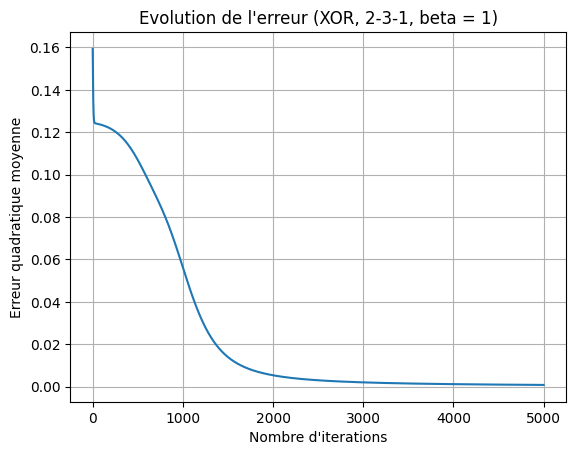

In [7]:
# 7. Visualisation de l'erreur
plt.plot(losses)
plt.title("Evolution de l'erreur (XOR, 2-3-1, beta = 1)")
plt.xlabel("Nombre d'iterations")
plt.ylabel("Erreur quadratique moyenne")
plt.grid(True)
plt.show()

In [8]:
# 8. Test final
Y_hat, _ = forward(X, params)
classes = (Y_hat >= 0.5).astype(int)
print("x1 x2 |  y_hat  | classe")
for j in range(4):
    print(f" {X[0, j]}  {X[1, j]} | {Y_hat[0, j]:.4f} |   {classes[0, j]}")
print("Taux de bonnes classifications :", np.mean(classes == Y) * 100, "%")

x1 x2 |  y_hat  | classe
 0  0 | 0.0218 |   0
 0  1 | 0.9577 |   1
 1  0 | 0.9608 |   1
 1  1 | 0.0527 |   0
Taux de bonnes classifications : 100.0 %


In [9]:
# 9. Expériences (questions de synthèse)
def entrainer(sizes, beta, seed=42, scale=1.0, n_iter=5000):
    p = initialisation(sizes, seed, scale)
    L = []
    for i in range(n_iter):
        Yh, c = forward(X, p)
        L.append(mse_loss(Y, Yh))
        p = update(p, backward(X, Y, Yh, c, p), beta)
    Yh, _ = forward(X, p)
    return L, np.mean((Yh >= 0.5) == Y)

# a) influence du taux d'apprentissage
for b in [0.01, 0.1, 0.5, 1, 5, 10, 50]:
    L, acc = entrainer([2, 3, 1], b)
    print(f"beta = {b:5} | erreur finale = {L[-1]:.5f} | accuracy = {acc*100:.0f} %")

beta =  0.01 | erreur finale = 0.12400 | accuracy = 50 %
beta =   0.1 | erreur finale = 0.10684 | accuracy = 75 %
beta =   0.5 | erreur finale = 0.00301 | accuracy = 100 %
beta =     1 | erreur finale = 0.00082 | accuracy = 100 %
beta =     5 | erreur finale = 0.00010 | accuracy = 100 %
beta =    10 | erreur finale = 0.00005 | accuracy = 100 %
beta =    50 | erreur finale = 0.00001 | accuracy = 100 %


In [10]:
# b) influence du nombre de neurones cachés (5 initialisations différentes)
for h in [1, 2, 3, 4, 8]:
    accs = []
    for s in [42, 0, 1, 2, 3]:
        L, acc = entrainer([2, h, 1], 1, seed=s)
        accs.append(int(acc * 100))
    print(f"{h} neurone(s) caché(s) | accuracy par graine : {accs}")

1 neurone(s) caché(s) | accuracy par graine : [75, 75, 75, 75, 75]
2 neurone(s) caché(s) | accuracy par graine : [100, 50, 50, 50, 75]
3 neurone(s) caché(s) | accuracy par graine : [100, 100, 50, 100, 100]
4 neurone(s) caché(s) | accuracy par graine : [100, 100, 100, 100, 100]
8 neurone(s) caché(s) | accuracy par graine : [100, 100, 100, 100, 100]
